# Can We Guess Next Week's Price?



In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pharmacli import model            # all the machine learning lives here
from pharmacli.frame import load

plt.rcParams.update({"figure.figsize": (8, 3.4), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": .3,
                     "axes.spines.top": False, "axes.spines.right": False})

d = model.features(load("../pharmacli.db"))
Xtr, Xte, ytr, yte = model.temporal_split(d)

print(f"We have {len(d):,} rows to learn from.")
print(f"In {d.y.mean()*100:.0f} out of 100 of them, the price jumped 5% or more the next week.")
print(f"We train on the early weeks ({len(Xtr):,} rows)")
print(f"and test on the later weeks ({len(Xte):,} rows) -- never the other way round.")

We have 995,678 rows to learn from.
In 4 out of 100 of them, the price jumped 5% or more the next week.
We train on the early weeks (754,737 rows)
and test on the later weeks (240,941 rows) -- never the other way round.


---
## Question 1 - What is the best clue that a price is about to change?

how old is the current price?

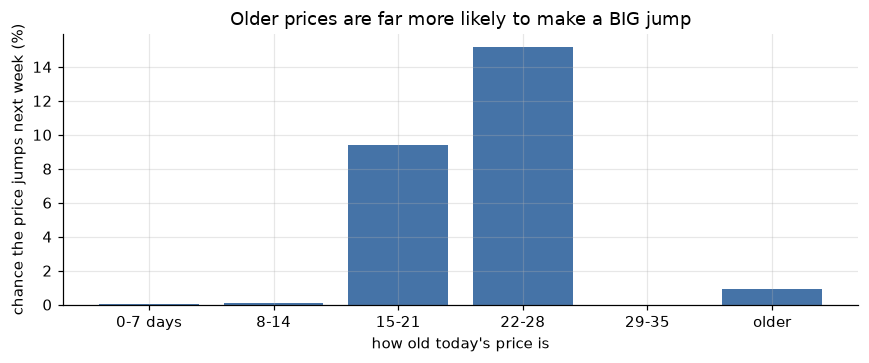

Price set this week:        0.0% chance it changes next week
Price set 22-28 days ago:  15.2% chance it changes next week


In [2]:
buckets = pd.cut(d.age_days, [-1, 7, 14, 21, 28, 35, 10000],
                 labels=["0-7 days", "8-14", "15-21", "22-28", "29-35", "older"])
odds = d.groupby(buckets, observed=True).y.mean()

fig, ax = plt.subplots()
ax.bar(odds.index.astype(str), odds * 100, color="#4573a7")
ax.set(ylabel="chance the price jumps next week (%)", xlabel="how old today's price is",
       title="Older prices are far more likely to make a BIG jump")
plt.tight_layout(); plt.show()

print(f"Price set this week:      {odds.iloc[0]*100:5.1f}% chance it changes next week")
print(f"Price set 22-28 days ago: {odds.iloc[3]*100:5.1f}% chance it changes next week")



A price set this week almost never makes a big jump next week

A price that is 22 to 28 days old jumps **15 in 100** times. 

The government updates this file on a **monthly schedule**.


---
## Question 2 - Is our model better than just guessing?



In [ ]:
base = model.baselines(Xtr, Xte, ytr, yte)
pipe = model.pipeline().fit(Xtr, ytr)
proba = pipe.predict_proba(Xte)[:, 1]
scores = model.scores(yte, proba, model.best_threshold(pipe, Xtr, ytr))

# Random guessing scores about 0.05.
print(f"Always guess 'no change':      {base.loc['always_no', 'PR-AUC']:.2f}")
print(f"Guess using ONLY the calendar: {base.loc['calendar_only', 'PR-AUC']:.2f}")
print(f"Our full model:                {scores['PR-AUC']:.2f}")
print()
print(f"Out of every 100 real jumps, our model catches {scores['recall']*100:.0f}.")
print(f"When it cries wolf, it is right {scores['precision']*100:.0f} times out of 100.")

Always guess 'no change':      0.04
Guess using ONLY the calendar: 0.16
Our full model:                0.40

Out of every 100 real jumps, our model catches 49.
When it cries wolf, it is right 39 times out of 100.


 **Yes - about 2.5x better than a calendar alone.**

**PR-AUC**: random guessing would score about 0.05.

Our model roughly **doubles** what you get from knowing the date and nothing
else. So it did learn something real about the medicines.

---
## Question 3 - What is the model *actually* learning?



In [4]:
# We first asked "will the price move at all?" -- and a calendar-only model
# scored almost as well as the full model. That is a warning sign.
print("Old question: 'will the price move AT ALL?'")
print("   calendar only .... 0.99")
print("   full model ....... 1.00     <- the drug data added almost nothing")
print()
print("New question: 'will the price move by 5% OR MORE?'")
print(f"   calendar only .... {base.loc['calendar_only', 'PR-AUC']:.2f}")
print(f"   full model ....... {scores['PR-AUC']:.2f}     <- now the drug data matters")

Old question: 'will the price move AT ALL?'
   calendar only .... 0.99
   full model ....... 1.00     <- the drug data added almost nothing

New question: 'will the price move by 5% OR MORE?'
   calendar only .... 0.16
   full model ....... 0.40     <- now the drug data matters




Asking "will the price move at all?" was the wrong question. The government
publishes on a schedule, and that schedule is public.

So we changed the question to "will it move **a lot**?"

/home/alanj/Documents/pythonprojects/pharmacli/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


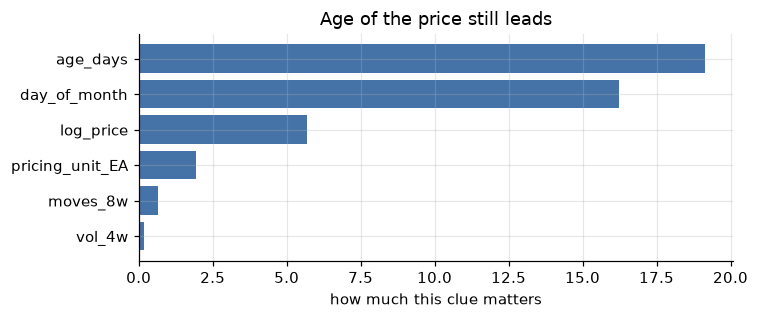

In [5]:
sv, names, sample = model.explain(pipe, Xte, n=1500)
imp = pd.Series(np.abs(sv.values).mean(0), index=names).sort_values().tail(6)
clean = [n.split("__")[-1] for n in imp.index]

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(clean, imp.values, color="#4573a7")
ax.set(xlabel="how much this clue matters", title="Age of the price still leads")
plt.tight_layout(); plt.show()

---
## Question 4 - Would a pharmacist actually make money using this?



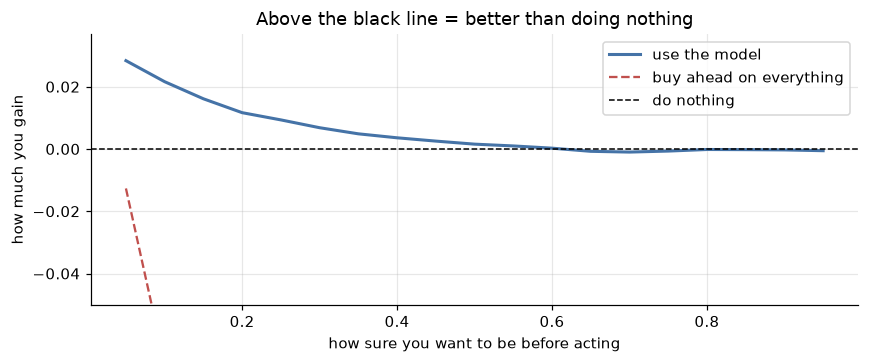

Using the model beats doing nothing when you act on predictions
between 0.05 and 0.60 confidence.
Outside that range, you are better off ignoring it.


In [6]:
nb_curve = model.net_benefit(yte, proba)
best = nb_curve[nb_curve.model > nb_curve.treat_none]

fig, ax = plt.subplots()
ax.plot(nb_curve.index, nb_curve.model, lw=2, color="#4573a7", label="use the model")
ax.plot(nb_curve.index, nb_curve.treat_all, ls="--", color="#c0504d", label="buy ahead on everything")
ax.axhline(0, ls="--", color="k", lw=1, label="do nothing")
ax.set(xlabel="how sure you want to be before acting", ylabel="how much you gain",
       ylim=(-0.05, max(nb_curve.model) * 1.3),
       title="Above the black line = better than doing nothing")
ax.legend(); plt.tight_layout(); plt.show()

print(f"Using the model beats doing nothing when you act on predictions")
print(f"between {best.index.min():.2f} and {best.index.max():.2f} confidence.")
print("Outside that range, you are better off ignoring it.")

### **Yes, but only inside a narrow band**

That band is why `pharmacli forecast` defaults to 0.25 and not 0.5. 

---
## Question 5 - When it is confidently wrong, what does it get wrong?


In [7]:
res = pd.DataFrame({"p": proba, "y": yte.to_numpy()}, index=Xte.index)
wrong = res[(res.p > 0.9) & (res.y == 0)]

print(f"{len(wrong):,} times the model was over 90% sure a price would jump, and it did not.")
print(f"That is {len(wrong)/len(res)*100:.1f}% of all its guesses.")
print()
print("A few of them:")
print(d.loc[wrong.nlargest(4, "p").index, ["description", "age_days", "rate_class"]].to_string(index=False))

8 times the model was over 90% sure a price would jump, and it did not.
That is 0.0% of all its guesses.

A few of them:
       description  age_days rate_class
SILVADENE 1% CREAM      28.0          B
SILVADENE 1% CREAM      21.0          B
SILVADENE 1% CREAM      49.0          B
SILVADENE 1% CREAM      14.0          B


###  only 8 times out of 240,941. And it is the same drug.

Price jump on only one medicine over at times and the model is not wrong or loud about one cream. This is a mistake and it is not scattered, model is rarely confident and when it is wrong it is wrong about one cream in specific.

---
A good score is not a good decision. We had to check separately whether acting on the model beats doing nothing and it only does inside a narrow band.